# GHZ state preparation on a neutral-atom QPU: sequential gates vs. cluster state + feed-forward

Two ways of preparing an $n$-qubit GHZ state $\;|\mathrm{GHZ}_n\rangle = (|0\ldots0\rangle + |1\ldots1\rangle)/\sqrt2$ are simulated
on a model of a neutral-atom quantum computer and compared with and without errors.

| | Method A: sequential | Method B: cluster + feed-forward |
|---|---|---|
| atoms used | $n$ | $n$ (ancillas are reset and reused) |
| entangling steps | $\approx n/2$ sequential (move + CNOT), grown from the centre outwards | 2 parallel layers of (move + CZ), then 1 layer of (move + CNOT) |
| mid-circuit measurements | none | $\lfloor (n-1)/2 
floor$ ancillas, measured in the X basis, then reset |
| classical feed-forward | none | Pauli-X corrections from the parity of the outcomes |
| duration scales as | $\sim (n/2)\,(t_\mathrm{move}+t_\mathrm{CZ})$ | $\sim 3\,t_\mathrm{move} + t_\mathrm{measure} + t_\mathrm{reset}$ (constant in $n$) |

**Physical model.** Every operation has a duration; the circuit is scheduled *as late as possible* (ALAP) and every idle gap is filled
with an explicit `Delay`. Decoherence ($T_1$, $T_2$) is applied for the duration of every gate, move and delay.
On top of that: a phase-flip error on each CZ, depolarizing errors on single-qubit gates and on transported atoms,
and a readout error on the ancilla measurements.

**How to use.** Edit the parameters in the first code cell, run everything. Every later section is independent enough to be
re-run on its own after a change. The last section sweeps the GHZ size and plots both methods against each other.

In [29]:
# ==========================================================================
#  Parameters of the physical system  -  edit here and rerun the notebook
# ==========================================================================
# All times are in seconds.

# --- Operation durations ---
GATE_DURATIONS = {
    "h":       0,      # single-qubit gate (Raman / microwave)
    "x":       0,
    "cz":      0,    # Rydberg CZ gate
    "measure": 100e-6,    # mid-circuit fluorescence readout of an ancilla
    "move":    200e-6,    # tweezer transport of an atom next to its partner
    "reset":   0,         # re-initialisation of a measured ancilla to |0>
}

# --- Coherence: applied for the duration of every operation and every wait ---
T1 = 1000          # amplitude-damping time (very long for hyperfine qubits)
T2 = 0.1        # dephasing time.  Z-flip probability during a wait t is  p = (1 - exp(-t/T2)) / 2

# --- Gate and readout errors ---
CZ_PHASE_FLIP_PROB      = 0.0005    # independent Z flip on each of the two atoms of a CZ gate
SINGLE_QUBIT_DEPOL_PROB = 0    # depolarizing error on H and X gates
MOVE_DEPOL_PROB         = 0    # depolarizing error on a transported atom (heating)
READOUT_ERROR_PROB      = 0.0005    # probability that an ancilla measurement outcome is reported wrong

# --- Simulation settings ---
N_GHZ       = 6              # GHZ size for the single-run section
SWEEP_SIZES = range(2, 13, 2)    # GHZ sizes for the final comparison
SHOTS       = 1000           # the returned density matrix is the average over the shots
N_BATCHES   = 10             # shots are split into this many independent batches -> error bar on the fidelity
SIM_METHOD  = "statevector"  # "statevector":    noise is sampled per shot (fast, ~1 % statistical error on the fidelity)
                             # "density_matrix": noise applied exactly, only measurement outcomes are sampled (slow beyond ~9 atoms)
DT = 1e-9                    # time step of the scheduler

In [30]:
import functools
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import Gate, Delay, Parameter, Reset
from qiskit.circuit.classical import expr
from qiskit.circuit.controlflow import IfElseOp
from qiskit.circuit.library import XGate, HGate, CZGate, Measure
from qiskit.transpiler import Target, InstructionProperties, PassManager
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.transpiler.passes.scheduling import ALAPScheduleAnalysis, PadDelay
from qiskit.quantum_info import Statevector, DensityMatrix, state_fidelity, average_gate_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, ReadoutError, pauli_error, depolarizing_error,
                              thermal_relaxation_error, LocalNoisePass)

warnings.filterwarnings("ignore", category=DeprecationWarning)

## 1. Circuits

Both builders return `(circuit, ghz_qubits)`: the circuit and the list of qubits that end up holding the GHZ state.

The `MoveGate` is a one-qubit placeholder that does nothing to the state but takes `GATE_DURATIONS["move"]`.
The scheduler orders operations only through shared qubits, not through the order they are written in. So *which* atom is
moved sets the timing: moving an atom that is already in the GHZ chain has to wait for that atom's previous CZ / H,
which makes the steps sequential. Moving a fresh atom would let all moves run in parallel at the start.

**Cluster correction rule.** The cluster is built on the atoms $0 \ldots L-1$ ($L = n$ for odd $n$, $n-1$ for even $n$).
After the X-basis measurement of the odd atoms (outcomes $m_0, m_1, \ldots$) the even atoms are in a GHZ state up to Pauli-X flips:
even atom $2j$ needs an X iff $m_0 \oplus \ldots \oplus m_{j-1} = 1$. The measured atoms are then reset to $|0
angle$ and each
is joined to the GHZ state by a CNOT from its left neighbour (for even $n$ the last, unused atom joins the same way).

In [31]:
class MoveGate(Gate):
    '''Transport one atom with an optical tweezer.

    Identity on the atom, but it has a duration, so the scheduler accounts for it
    and the noise model can attach decoherence and a heating error to it.
    '''
    def __init__(self):
        super().__init__("move", 1, [], label="move")

    def _define(self):                       # the simulator sees it as "do nothing"
        self.definition = QuantumCircuit(1)


def ideal_ghz_state(n):
    '''|GHZ_n> = (|0...0> + |1...1>) / sqrt(2)'''
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(1, n):
        qc.cx(0, i)
    return Statevector(qc)


def sequential_ghz_circuit(n_ghz):
    '''Method A: the textbook GHZ recipe - one H, then a chain of CNOTs, grown from the centre outwards.

    In every step the atom at the end of the chain (already entangled) is moved next to a
    fresh atom in |0>, and a CNOT copies the GHZ bit onto it. The move waits for the previous
    CNOT on that atom, so the steps are sequential. The two arms run in parallel,
    so the depth is ~n/2 (move + CNOT) steps instead of n.
    The scheduler writes each CNOT in the native gates as  H - CZ - H  on the fresh atom.
    '''
    qc = QuantumCircuit(n_ghz)
    centre = n_ghz // 2
    qc.h(centre)                                  # centre atom in |+>
    qc.append(MoveGate(), [centre])
    qc.cx(centre, centre - 1)
    for step in range(1, n_ghz):
        for old, new in ((centre + step - 1, centre + step),     # right arm
                         (centre - step, centre - step - 1)):    # left arm
            if 0 <= new < n_ghz:
                qc.append(MoveGate(), [old])      # move the chain end to the fresh atom
                qc.cx(old, new)                   # copy the GHZ bit onto the fresh atom
    return qc, list(range(n_ghz))


def cluster_ghz_circuit(n_ghz):
    '''Method B: linear cluster -> X-measurement of the odd atoms -> feed-forward -> reuse the ancillas.

    A linear cluster of the atoms 0..L-1 (L = n_ghz, or n_ghz - 1 if n_ghz is even) is built with two
    parallel layers of (move + CZ). Measuring the odd atoms in the X basis leaves the even atoms in a
    GHZ state after the X corrections described above. The measured atoms are reset to |0> and a third
    layer of (move + CNOT) copies the GHZ bit onto them, so all n_ghz atoms end up in the GHZ state.
    '''
    L = n_ghz if n_ghz % 2 else n_ghz - 1
    ancillas = list(range(1, L - 1, 2))

    q = QuantumRegister(n_ghz, "q")
    m = ClassicalRegister(len(ancillas), "m")
    qc = QuantumCircuit(q, m)

    qc.h(q[:L])
    for first in (0, 1):                     # even bonds, then odd bonds
        for i in range(first, L - 1, 2):
            qc.append(MoveGate(), [i])
            qc.cz(i, i + 1)
    qc.barrier()

    for k, a in enumerate(ancillas):         # X-basis measurement of the ancillas
        qc.h(a)
        qc.measure(a, m[k])
    qc.barrier()

    for j in range(1, len(ancillas) + 1):    # feed-forward corrections on the even atoms
        parity = functools.reduce(expr.bit_xor, [m[i] for i in range(1, j)], expr.lift(m[0]))
        with qc.if_test(parity):
            qc.x(2 * j)
    for a in ancillas:                       # reuse the ancillas
        qc.reset(a)
    qc.barrier()

    for i in range(0, n_ghz - 1, 2):         # copy the GHZ bit onto the odd atoms
        qc.append(MoveGate(), [i + 1])
        qc.cx(i, i + 1)
    return qc, list(range(n_ghz))


## 2. Physical model: scheduling, noise and simulation

* `schedule_circuit` builds a transpiler `Target` with the durations of the first cell, schedules ALAP and pads idle time with `Delay`s.
* `idle_error` turns the duration of every gate, move and delay into a $T_1/T_2$ channel (`LocalNoisePass` inserts it into the circuit).
* `build_noise_model` holds the time-independent errors (CZ phase flips, single-qubit depolarizing, readout).
* `simulate` runs one circuit, with or without errors, and returns the density matrix of the GHZ qubits, its fidelity and the circuit duration.

**Error bars.** The shots are split into `N_BATCHES` independent batches (each with its own random seed). The error bar is the
standard error of the mean of the batch fidelities. With `"statevector"` it covers the sampling of errors and of measurement outcomes;
with `"density_matrix"` only the measurement outcomes are sampled, so it is zero for the sequential circuit.

In [32]:
def build_target(n_qubits):
    '''Transpiler target of an all-to-all device with the durations of the first cell.'''
    target = Target(dt=DT)
    single = lambda t: {(i,): InstructionProperties(duration=t) for i in range(n_qubits)}
    pair = lambda t: {(i, j): InstructionProperties(duration=t)
                      for i in range(n_qubits) for j in range(n_qubits) if i != j}
    target.add_instruction(HGate(), single(GATE_DURATIONS["h"]))
    target.add_instruction(XGate(), single(GATE_DURATIONS["x"]))
    target.add_instruction(Measure(), single(GATE_DURATIONS["measure"]))
    target.add_instruction(Reset(), single(GATE_DURATIONS["reset"]))
    target.add_instruction(CZGate(), pair(GATE_DURATIONS["cz"]))
    target.add_instruction(MoveGate(), single(GATE_DURATIONS["move"]))
    target.add_instruction(Delay(Parameter("t")), single(0))
    target.add_instruction(IfElseOp, name="if_else")
    return target


def schedule_circuit(circuit):
    '''ALAP-schedule the circuit and fill every idle gap with an explicit Delay.'''
    target = build_target(circuit.num_qubits)
    pm = generate_preset_pass_manager(optimization_level=0, target=target)
    pm.scheduling = PassManager([ALAPScheduleAnalysis(target=target), PadDelay(target=target)])
    return pm.run(circuit)


def operation_duration(op):
    '''Duration in seconds of one instruction of a scheduled circuit.'''
    if op.name == "delay":
        return op.duration * DT
    if op.name == "if_else":
        return max(circuit_duration(block) for block in op.blocks)
    return GATE_DURATIONS.get(op.name, 0.0)


def circuit_duration(circuit):
    '''Wall-clock time of a scheduled circuit = its longest qubit time line (seconds).'''
    per_qubit = np.zeros(circuit.num_qubits)
    for inst in circuit.data:
        for qubit in inst.qubits:
            per_qubit[circuit.find_bit(qubit).index] += operation_duration(inst.operation)
    return per_qubit.max()


def idle_error(op, qubits):
    '''T1/T2 decay for the duration of an operation, plus a heating error on a moved atom.'''
    t = operation_duration(op)
    if t <= 0:
        return None
    err = thermal_relaxation_error(T1, T2, t)
    err = functools.reduce(lambda a, b: a.expand(b), [err] * len(qubits))
    if op.name == "move":
        err = err.compose(depolarizing_error(MOVE_DEPOL_PROB, 1))
    return err


def build_noise_model():
    '''Errors that do not depend on time.'''
    noise = NoiseModel()
    z_flip = pauli_error([("Z", CZ_PHASE_FLIP_PROB), ("I", 1 - CZ_PHASE_FLIP_PROB)])
    noise.add_all_qubit_quantum_error(z_flip.tensor(z_flip), "cz")
    noise.add_all_qubit_quantum_error(depolarizing_error(SINGLE_QUBIT_DEPOL_PROB, 1), ["h", "x"])
    p = READOUT_ERROR_PROB
    noise.add_all_qubit_readout_error(ReadoutError([[1 - p, p], [p, 1 - p]]))
    return noise


def simulate(circuit, ghz_qubits, noisy):
    '''Schedule, add noise (optional), run, and return fidelity +- error, duration, density matrix and scheduled circuit.'''
    scheduled = schedule_circuit(circuit)
    to_run = scheduled.copy()
    if noisy:
        to_run = PassManager([LocalNoisePass(idle_error, op_types=(Gate, Delay))]).run(to_run)
    to_run.save_density_matrix(ghz_qubits, label="rho")

    backend = AerSimulator(method=SIM_METHOD,
                           noise_model=build_noise_model() if noisy else None,
                           shot_branching_enable=(SIM_METHOD == "density_matrix"))
    compiled = transpile(to_run, backend, optimization_level=0)
    result = backend.run([compiled] * N_BATCHES, shots=SHOTS // N_BATCHES).result()   # one job, independent seeds

    target = ideal_ghz_state(len(ghz_qubits))
    batch_rhos = [DensityMatrix(result.data(i)["rho"]) for i in range(N_BATCHES)]
    batch_fids = [state_fidelity(r, target) for r in batch_rhos]
    rho = DensityMatrix(np.mean([r.data for r in batch_rhos], axis=0))   # average over all shots
    return {
        "fidelity": state_fidelity(rho, target),     # equals the mean of batch_fids (fidelity is linear in rho)
        "fidelity_err": np.std(batch_fids, ddof=1) / np.sqrt(N_BATCHES),
        "duration_us": circuit_duration(scheduled) * 1e6,
        "rho": rho,
        "scheduled": scheduled,
    }


def ghz_summary(rho):
    '''The three numbers that characterise a GHZ density matrix (fidelity = (P0 + P1)/2 + Re coherence).'''
    d = rho.data
    return {"P(0..0)": d[0, 0].real, "P(1..1)": d[-1, -1].real, "|coherence|": abs(d[0, -1])}


def plot_density_matrix(ax, rho, title):
    '''|rho| on a log colour scale so that the small noise-induced entries are visible next to the 0.5 corners.'''
    magnitude = np.abs(rho.data)
    image = ax.imshow(magnitude, cmap="Blues", norm=LogNorm(vmin=1e-4, vmax=0.5))
    ax.set_title(title)
    ax.set_xticks([0, len(magnitude) - 1], ["|0…0⟩", "|1…1⟩"])
    ax.set_yticks([0, len(magnitude) - 1], ["⟨0…0|", "⟨1…1|"])
    return image

## 3. Sanity checks on the error parameters

Translate the error parameters into the numbers usually quoted for a device.

In [33]:
z_flip = pauli_error([("Z", CZ_PHASE_FLIP_PROB), ("I", 1 - CZ_PHASE_FLIP_PROB)])
cz_channel = z_flip.tensor(z_flip).to_quantumchannel()
print(f"CZ average gate fidelity (phase flips only): {average_gate_fidelity(cz_channel):.4f}")

for name in ("cz", "move", "measure"):
    t = GATE_DURATIONS[name]
    print(f"Z-flip probability during one '{name}' ({t * 1e6:6.1f} us): {(1 - np.exp(-t / T2)) / 2:.3%}")

CZ average gate fidelity (phase flips only): 0.9992
Z-flip probability during one 'cz' (   0.0 us): 0.000%
Z-flip probability during one 'move' ( 200.0 us): 0.100%
Z-flip probability during one 'measure' ( 100.0 us): 0.050%


## 4. Single run at `N_GHZ`

### The two circuits (before scheduling)

6-qubit GHZ:  sequential uses 6 atoms,  cluster + feed-forward uses 6 atoms (GHZ on [0, 1, 2, 3, 4, 5])


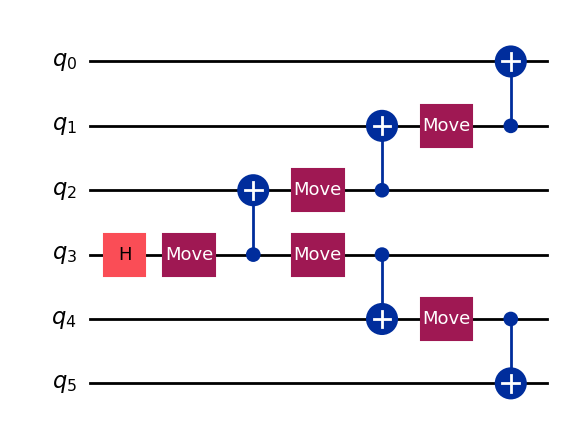

In [34]:
seq_circuit, seq_ghz = sequential_ghz_circuit(N_GHZ)
clu_circuit, clu_ghz = cluster_ghz_circuit(N_GHZ)
print(f"{N_GHZ}-qubit GHZ:  sequential uses {seq_circuit.num_qubits} atoms,  "
      f"cluster + feed-forward uses {clu_circuit.num_qubits} atoms (GHZ on {clu_ghz})")
seq_circuit.draw("mpl", fold=-1)

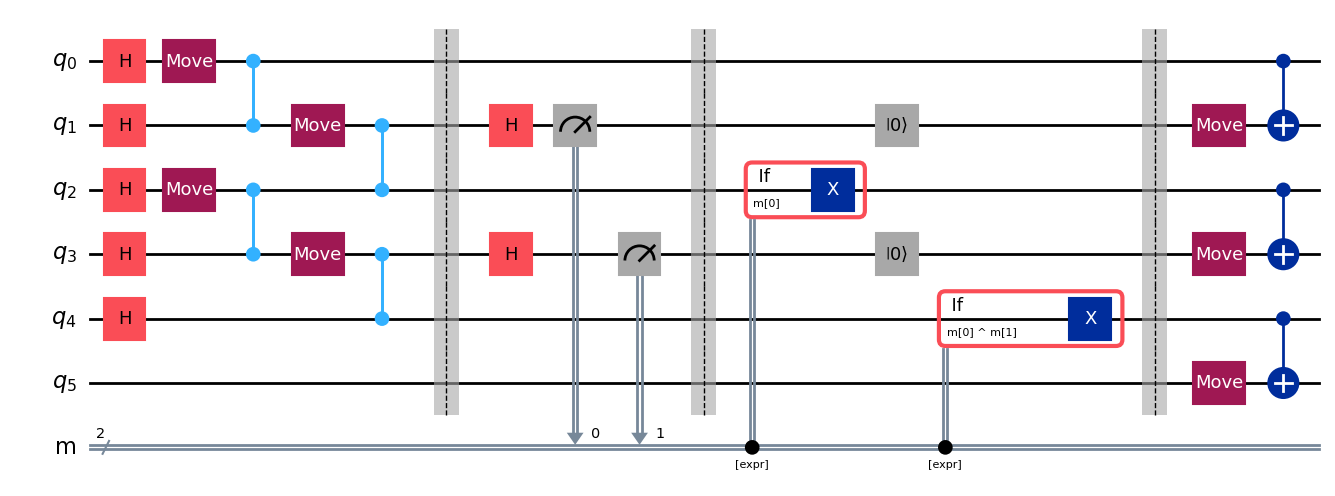

In [7]:
clu_circuit.draw("mpl", fold=-1)

### Run: each circuit with and without errors

In [35]:
runs = {}
for method, (circuit, ghz) in {"sequential": (seq_circuit, seq_ghz), "cluster": (clu_circuit, clu_ghz)}.items():
    for noise in ("ideal", "noisy"):
        runs[(method, noise)] = simulate(circuit, ghz, noisy=(noise == "noisy"))

table = pd.DataFrame({key: {"fidelity": r["fidelity"], "± err": r["fidelity_err"],
                             "duration [us]": r["duration_us"], **ghz_summary(r["rho"])}
                      for key, r in runs.items()}).T
table.index.names = ["method", "noise"]
table.round(4)

fidelity   ± err  duration [us]  P(0..0)  P(1..1)  \
method     noise                                                      
sequential ideal     1.000  0.0000          600.0   0.5000   0.5000   
           noisy     0.990  0.0039          600.0   0.4990   0.4990   
cluster    ideal     1.000  0.0000          700.0   0.5000   0.5000   
           noisy     0.973  0.0037          700.0   0.4955   0.4955   

                  |coherence|  
method     noise               
sequential ideal       0.5000  
           noisy       0.4910  
cluster    ideal       0.5000  
           noisy       0.4775

### Scheduled circuits

What the simulator actually ran: the delays are where the idle atoms decohere. Note how, in the sequential circuit,
the outer atoms wait for the inner ones, and in the cluster circuit all atoms wait for the ancilla measurement before the last layer.

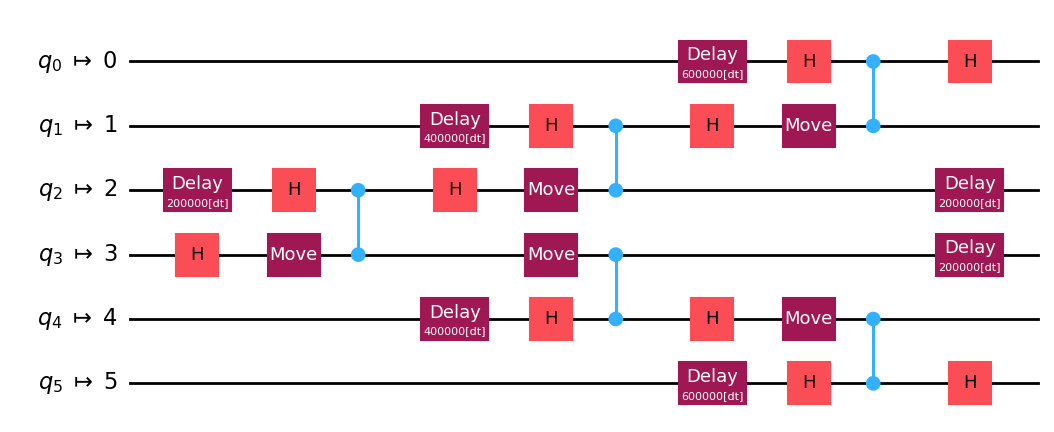

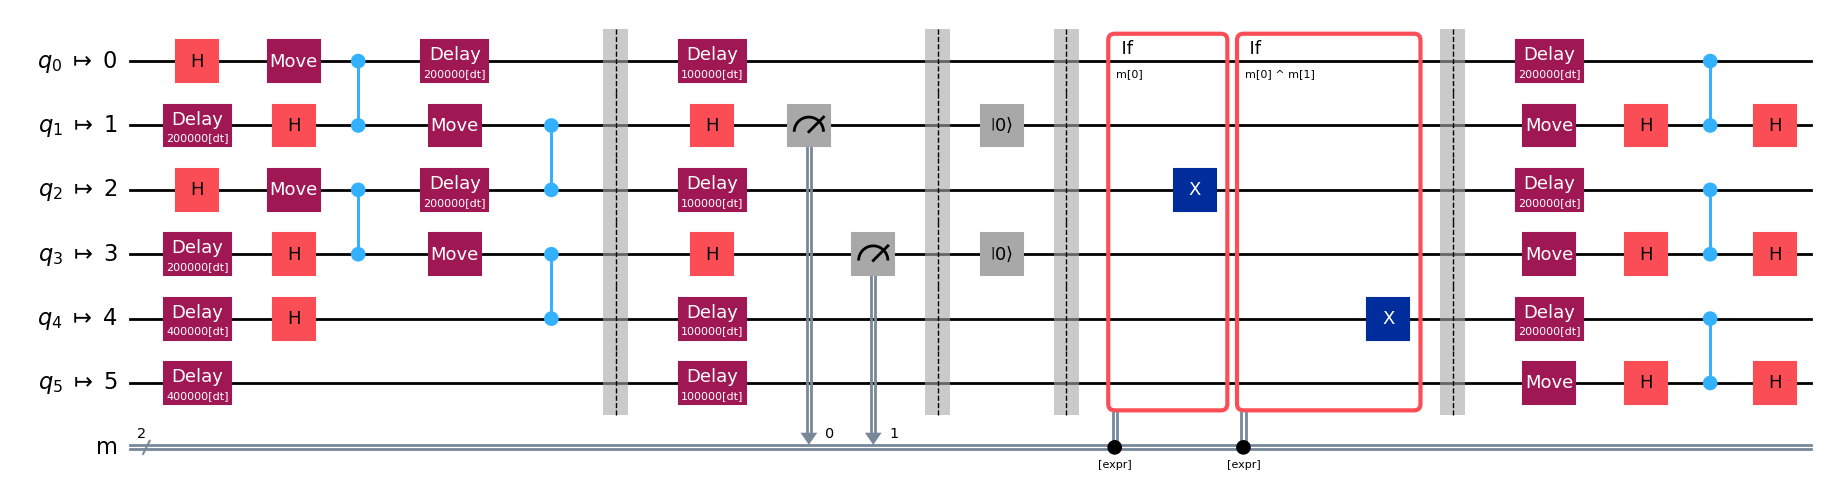

In [36]:
# The drawer places gates in columns, not by time. "right" pushes every gate as late as possible,
# which matches the ALAP schedule of the sequential circuit (each H lands next to its CZ).
# The cluster circuit is drawn left-justified, because "right" would stagger its simultaneous measurements.
display(runs[("sequential", "noisy")]["scheduled"].draw("mpl", fold=-1, idle_wires=False, justify="right"))
display(runs[("cluster", "noisy")]["scheduled"].draw("mpl", fold=-1, idle_wires=False))

### Density matrices of the GHZ qubits

Real part of $\rho$ on the GHZ qubits (the imaginary part is zero up to sampling noise).
An ideal GHZ state has 0.5 in the four corners and 0 everywhere else; dephasing eats the off-diagonal corners,
bit flips and wrong corrections populate the other diagonal entries.

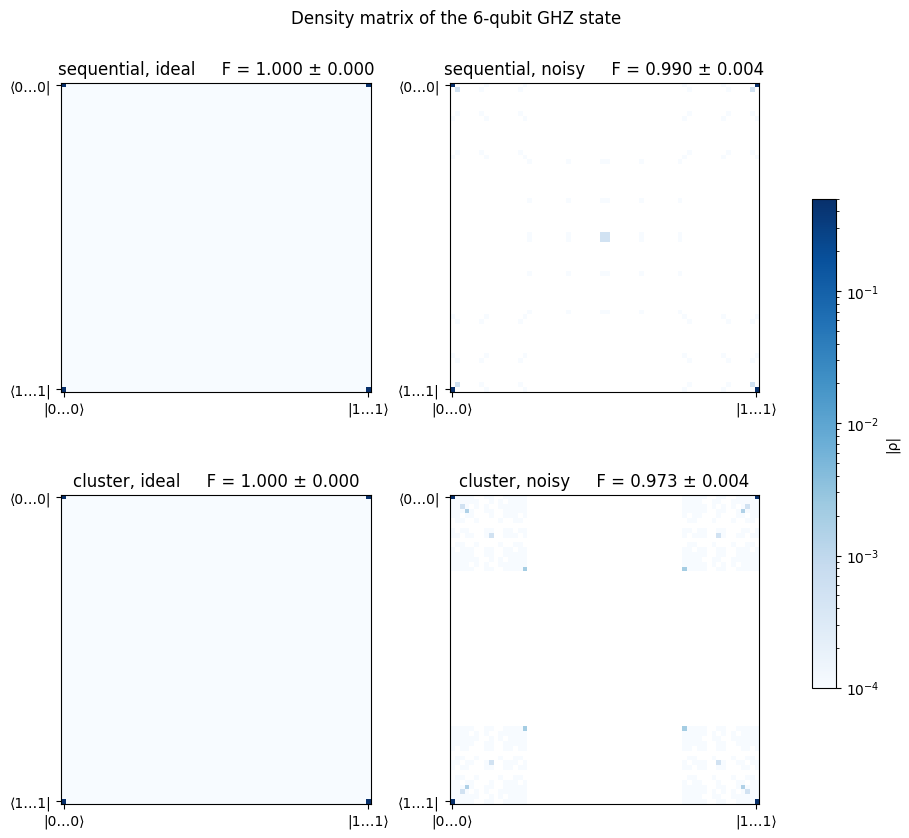

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8.5), constrained_layout=True)
for ax, (key, r) in zip(axes.flat, runs.items()):
    image = plot_density_matrix(ax, r["rho"], f"{key[0]}, {key[1]}     F = {r['fidelity']:.3f} ± {r['fidelity_err']:.3f}")
fig.colorbar(image, ax=axes, shrink=0.6, label="|ρ|")
fig.suptitle(f"Density matrix of the {N_GHZ}-qubit GHZ state")
plt.show()

## 5. Sweep over the GHZ size

Both methods are simulated for every size in `SWEEP_SIZES`, with and without errors.
The ideal runs should all give fidelity 1 (that is the check of the circuits and of the correction rule).

In [ ]:
rows = []
for n in SWEEP_SIZES:
    for method, builder in (("sequential", sequential_ghz_circuit), ("cluster", cluster_ghz_circuit)):
        circuit, ghz = builder(n)
        for noise in ["noisy"]: #("ideal", "noisy"):
            t_start = time.perf_counter()
            r = simulate(circuit, ghz, noisy=(noise == "noisy"))
            print(f"n = {n}  {method:<10}  {noise:<5}  F = {r['fidelity']:.3f}  ({time.perf_counter() - t_start:.1f} s)")
            rows.append({"n_ghz": n, "method": method, "noise": noise, "atoms": circuit.num_qubits,
                         "fidelity": r["fidelity"], "fidelity_err": r["fidelity_err"],
                         "duration_us": r["duration_us"]})

sweep = pd.DataFrame(rows)
sweep["F ± err"] = [f"{f:.3f} ± {e:.3f}" for f, e in zip(sweep.fidelity, sweep.fidelity_err)]
sweep.pivot(index="n_ghz", columns=["method", "noise"], values="F ± err")

n = 2  sequential  noisy  F = 0.997  (0.1 s)
n = 2  cluster     noisy  F = 0.997  (0.1 s)
n = 4  sequential  noisy  F = 0.997  (0.2 s)
n = 4  cluster     noisy  F = 0.993  (0.3 s)
n = 6  sequential  noisy  F = 0.991  (0.3 s)
n = 6  cluster     noisy  F = 0.975  (0.5 s)
n = 8  sequential  noisy  F = 0.980  (0.8 s)
n = 8  cluster     noisy  F = 0.973  (1.0 s)
n = 10  sequential  noisy  F = 0.975  (11.4 s)


n = 2  sequential  noisy  F = 0.999  (0.2 s)
n = 2  cluster     noisy  F = 0.997  (0.1 s)
n = 4  sequential  noisy  F = 0.993  (0.2 s)
n = 4  cluster     noisy  F = 0.996  (0.5 s)
n = 6  sequential  noisy  F = 0.992  (0.4 s)
n = 6  cluster     noisy  F = 0.984  (0.7 s)
n = 8  sequential  noisy  F = 0.977  (1.1 s)
n = 8  cluster     noisy  F = 0.987  (1.5 s)
n = 10  sequential  noisy  F = 0.970  (15.5 s)
n = 10  cluster     noisy  F = 0.976  (14.6 s)
n = 12  sequential  noisy  F = 0.958  (461.9 s)
n = 12  cluster     noisy  F = 0.960  (361.6 s)


method,sequential,cluster
noise,noisy,noisy
n_ghz,,
2,0.999 ± 0.001,0.997 ± 0.002
4,0.993 ± 0.002,0.996 ± 0.002
6,0.992 ± 0.002,0.984 ± 0.004
8,0.977 ± 0.004,0.987 ± 0.003
10,0.970 ± 0.006,0.976 ± 0.005
12,0.958 ± 0.006,0.960 ± 0.006


In [40]:
# Save the sweep (with the parameters it was run with) to sweep_results/<timestamp>.json
import json, os
from datetime import datetime

RESULTS_DIR = "sweep_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
results_file = os.path.join(RESULTS_DIR, f"ghz_sweep_{datetime.now():%Y%m%d_%H%M%S}.json")
with open(results_file, "w") as f:
    json.dump({"parameters": {"GATE_DURATIONS": GATE_DURATIONS, "T1": T1, "T2": T2,
                              "CZ_PHASE_FLIP_PROB": CZ_PHASE_FLIP_PROB,
                              "SINGLE_QUBIT_DEPOL_PROB": SINGLE_QUBIT_DEPOL_PROB,
                              "MOVE_DEPOL_PROB": MOVE_DEPOL_PROB, "READOUT_ERROR_PROB": READOUT_ERROR_PROB,
                              "SWEEP_SIZES": list(SWEEP_SIZES), "SHOTS": SHOTS, "N_BATCHES": N_BATCHES,
                              "SIM_METHOD": SIM_METHOD},
               "sweep": sweep.drop(columns="F ± err").to_dict(orient="records")}, f, indent=2)
print(f"saved to {results_file}")

# --- Load a saved sweep instead of recalculating (skip the sweep cell above, uncomment and set the file) ---
# results_file = os.path.join(RESULTS_DIR, "ghz_sweep_YYYYMMDD_HHMMSS.json")
# with open(results_file) as f:
#     saved = json.load(f)
# sweep = pd.DataFrame(saved["sweep"])
# print(saved["parameters"])

saved to sweep_results\ghz_sweep_20260930_164653.json


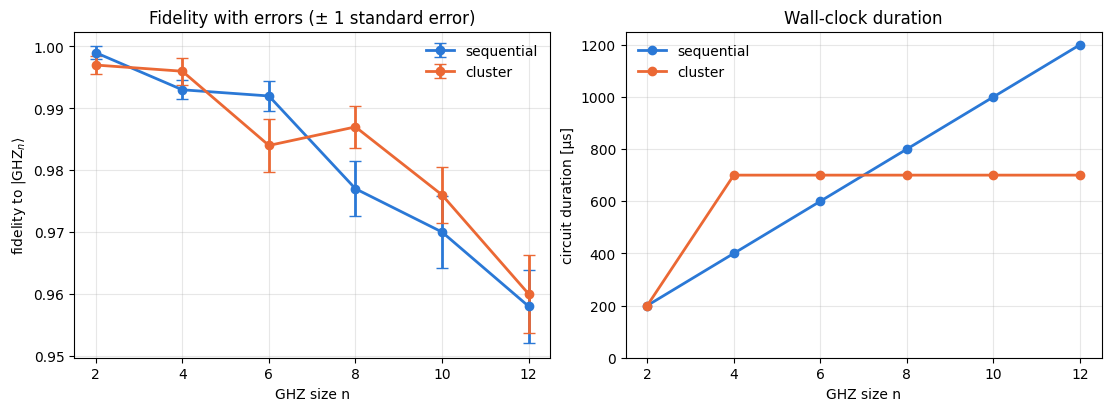

In [41]:
COLORS = {"sequential": "#2a78d6", "cluster": "#eb6834"}

fig, (ax_fid, ax_dur) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for method in COLORS:
    group = sweep[(sweep.method == method) & (sweep.noise == "noisy")]
    ax_fid.errorbar(group.n_ghz, group.fidelity, yerr=group.fidelity_err, fmt="o-", lw=2, ms=6, capsize=4,
                    color=COLORS[method], label=method)
    ax_dur.plot(group.n_ghz, group.duration_us, "o-", lw=2, ms=6, color=COLORS[method], label=method)

ax_fid.set(xlabel="GHZ size n", ylabel="fidelity to |GHZ$_n$⟩", title="Fidelity with errors (± 1 standard error)")
ax_dur.set(xlabel="GHZ size n", ylabel="circuit duration [µs]", title="Wall-clock duration", ylim=(0, None))
for ax in (ax_fid, ax_dur):
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
plt.show()

## 6. Large GHZ sizes with the Clifford (stabilizer) simulator

The simulators above store $2^N$ (statevector) or $4^N$ (density matrix) numbers, so every extra atom doubles the cost.
If every operation is a Clifford gate (H, X, CZ, CNOT, measurement, reset) and every error is a random Pauli flip,
the state can be tracked with the **stabilizer** method, whose cost grows only polynomially with the number of atoms.

**Error model of this section.** It is a simplified version of the one above that only uses Pauli errors. It takes its values from the first cell:

| where | error |
|---|---|
| every wait (`Delay`) and every `move` | Z flip with $p = (1 - e^{-t/T_2})/2$ (dephasing only, no $T_1$) |
| CZ gate | independent Z flip on each atom with `CZ_PHASE_FLIP_PROB` |
| ancilla measurement | outcome flipped with `READOUT_ERROR_PROB` (an X flip just before the measurement) |
| H, X, reset | no error |

**Fidelity without a density matrix.** After the noisy preparation, a *noiseless* inverse of the ideal GHZ circuit is appended
(CNOTs from the first GHZ atom to all others, then H), and all GHZ atoms are measured.
The inverse maps $|\mathrm{GHZ}_n\rangle$ to $|0\ldots0\rangle$, so the fraction of all-zero outcomes is exactly
$\langle \mathrm{GHZ}_n|\rho|\mathrm{GHZ}_n\rangle$, the same fidelity as above. Error bars come from batches as before.

Run sections 1 and 2 first (parameters, imports, circuits, physical model); this section reuses their functions.

In [19]:
# --- Settings for the Clifford sweep (physical parameters come from the first cell) ---
CLIFFORD_SWEEP_SIZES = range(2, 26, 2)   # GHZ sizes (~3 min; up to 40 takes ~7 min)
CLIFFORD_SHOTS       = 20000
CLIFFORD_BATCHES     = 10
CHECK_SIZES          = range(2, 5)       # sizes for the cross-check against the statevector simulator

In [20]:
def pauli_noise(op, qubits):
    '''Pauli-only errors: Z flip during waits (delay, move) and on both atoms of a CZ.'''
    if op.name in ("delay", "move"):
        p = (1 - np.exp(-operation_duration(op) / T2)) / 2
        return pauli_error([("Z", p), ("I", 1 - p)]) if p > 0 else None
    if op.name == "cz":
        z_flip = pauli_error([("Z", CZ_PHASE_FLIP_PROB), ("I", 1 - CZ_PHASE_FLIP_PROB)])
        return z_flip.tensor(z_flip)
    return None


def readout_flip(op, qubits):
    '''Readout error of an ancilla: X flip just before the measurement, so the reported outcome is wrong.'''
    return pauli_error([("X", READOUT_ERROR_PROB), ("I", 1 - READOUT_ERROR_PROB)])


def append_ghz_check(circuit, ghz_qubits):
    '''Noiseless inverse of the ideal GHZ preparation + measurement:  P(all zeros) = <GHZ|rho|GHZ>.'''
    check = ClassicalRegister(len(ghz_qubits), "check")
    circuit.add_register(check)
    for q in ghz_qubits[1:]:
        circuit.cx(ghz_qubits[0], q)
    circuit.h(ghz_qubits[0])
    circuit.measure(ghz_qubits, check)
    return circuit


def simulate_clifford(circuit, ghz_qubits, noisy, method="stabilizer"):
    '''Schedule, add Pauli noise (optional), append the GHZ check, run, and return fidelity +- error and duration.'''
    scheduled = schedule_circuit(circuit)
    to_run = scheduled.copy()
    if noisy:   # noise is inserted before the check is appended, so the check itself is noiseless
        to_run = PassManager([LocalNoisePass(pauli_noise, op_types=(Gate, Delay)),
                              LocalNoisePass(readout_flip, op_types=Measure, method="prepend")]).run(to_run)
    to_run = append_ghz_check(to_run, ghz_qubits)

    backend = AerSimulator(method=method)
    compiled = transpile(to_run, backend, optimization_level=0)
    shots = CLIFFORD_SHOTS // CLIFFORD_BATCHES
    result = backend.run([compiled] * CLIFFORD_BATCHES, shots=shots).result()

    all_zeros = "0" * len(ghz_qubits)
    batch_fids = [sum(c for key, c in result.get_counts(i).items() if key.split()[0] == all_zeros) / shots
                  for i in range(CLIFFORD_BATCHES)]          # "check" is the last register = first in the key
    return {
        "fidelity": np.mean(batch_fids),
        "fidelity_err": np.std(batch_fids, ddof=1) / np.sqrt(CLIFFORD_BATCHES),
        "duration_us": circuit_duration(scheduled) * 1e6,
    }

### Cross-check against the statevector simulator

The same noisy circuits (same Pauli error model, same fidelity check) are run with the `stabilizer` and the `statevector` method
at small sizes. The two columns should agree within the error bars; this confirms that the circuits are Clifford and that the stabilizer
simulation is valid for them. The ideal runs must give exactly 1.

In [16]:
# check_rows = []
# for n in CHECK_SIZES:
#     for name, builder in (("sequential", sequential_ghz_circuit), ("cluster", cluster_ghz_circuit)):
#         circuit, ghz = builder(n)
#         ideal = simulate_clifford(circuit, ghz, noisy=False)
#         stab = simulate_clifford(circuit, ghz, noisy=True, method="stabilizer")
#         sv = simulate_clifford(circuit, ghz, noisy=True, method="statevector")
#         check_rows.append({"n_ghz": n, "method": name, "ideal (stabilizer)": ideal["fidelity"],
#                            "noisy stabilizer": f"{stab['fidelity']:.3f} ± {stab['fidelity_err']:.3f}",
#                            "noisy statevector": f"{sv['fidelity']:.3f} ± {sv['fidelity_err']:.3f}",
#                            "difference / combined error": (stab["fidelity"] - sv["fidelity"])
#                                / np.hypot(stab["fidelity_err"], sv["fidelity_err"])})
# pd.DataFrame(check_rows).set_index(["n_ghz", "method"]).round(3)

### Sweep to large GHZ sizes

In [21]:
clifford_rows = []
for n in CLIFFORD_SWEEP_SIZES:
    for method, builder in (("sequential", sequential_ghz_circuit), ("cluster", cluster_ghz_circuit)):
        circuit, ghz = builder(n)
        t_start = time.perf_counter()
        r = simulate_clifford(circuit, ghz, noisy=True)
        print(f"n = {n:3d}  {method:<10}  F = {r['fidelity']:.3f} ± {r['fidelity_err']:.3f}  "
              f"({time.perf_counter() - t_start:.1f} s)")
        clifford_rows.append({"n_ghz": n, "method": method, "atoms": circuit.num_qubits, **r})

clifford_sweep = pd.DataFrame(clifford_rows)
clifford_sweep.pivot(index="n_ghz", columns="method", values=["fidelity", "fidelity_err", "duration_us"]).round(4)

n =   2  sequential  F = 1.000 ± 0.000  (1.2 s)
n =   2  cluster     F = 1.000 ± 0.000  (1.3 s)
n =   4  sequential  F = 0.999 ± 0.000  (2.5 s)
n =   4  cluster     F = 0.999 ± 0.000  (4.1 s)
n =   6  sequential  F = 0.998 ± 0.000  (4.0 s)
n =   6  cluster     F = 0.998 ± 0.000  (7.4 s)
n =   8  sequential  F = 0.998 ± 0.000  (5.9 s)
n =   8  cluster     F = 0.997 ± 0.000  (11.3 s)
n =  10  sequential  F = 0.997 ± 0.000  (7.5 s)
n =  10  cluster     F = 0.996 ± 0.000  (15.6 s)
n =  12  sequential  F = 0.997 ± 0.001  (9.2 s)
n =  12  cluster     F = 0.995 ± 0.001  (20.3 s)
n =  14  sequential  F = 0.996 ± 0.000  (11.3 s)
n =  14  cluster     F = 0.995 ± 0.000  (25.5 s)
n =  16  sequential  F = 0.995 ± 0.000  (12.8 s)
n =  16  cluster     F = 0.995 ± 0.001  (31.4 s)
n =  18  sequential  F = 0.995 ± 0.001  (14.6 s)
n =  18  cluster     F = 0.992 ± 0.001  (37.5 s)
n =  20  sequential  F = 0.992 ± 0.001  (16.6 s)
n =  20  cluster     F = 0.991 ± 0.001  (45.9 s)
n =  22  sequential  F = 0.99

fidelity            fidelity_err            duration_us           
method  cluster sequential      cluster sequential     cluster sequential
n_ghz                                                                    
2        0.9998     0.9998       0.0001     0.0001       200.0      200.0
4        0.9986     0.9994       0.0003     0.0002       700.0      400.0
6        0.9984     0.9984       0.0002     0.0003       700.0      600.0
8        0.9973     0.9980       0.0003     0.0003       700.0      800.0
10       0.9964     0.9969       0.0004     0.0003       700.0     1000.0
12       0.9949     0.9968       0.0005     0.0005       700.0     1200.0
14       0.9954     0.9961       0.0005     0.0004       700.0     1400.0
16       0.9945     0.9950       0.0005     0.0004       700.0     1600.0
18       0.9921     0.9950       0.0006     0.0007       700.0     1800.0
20       0.9910     0.9924       0.0007     0.0005       700.0     2000.0
22       0.9907     0.9910       0.0004     0.0005       700.0     2200.0
24       0.9912     0.9909       0.0005     0.0007       700.0     2400.0

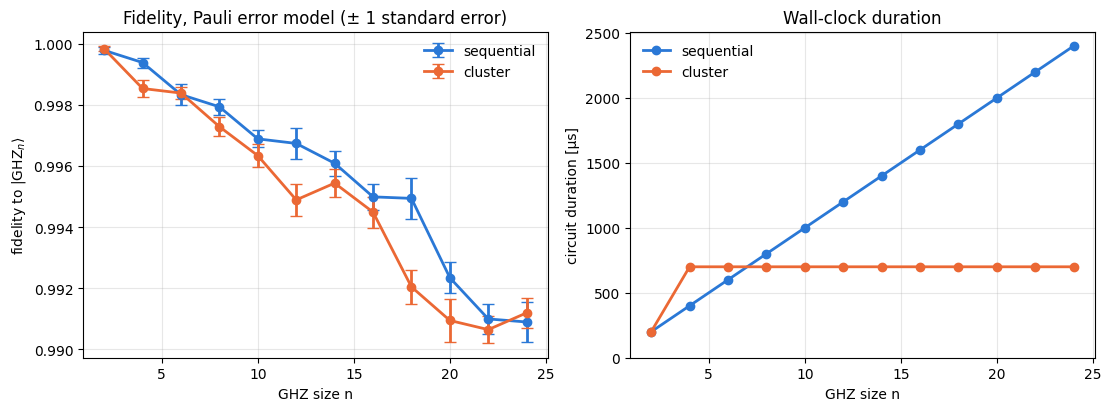

In [22]:
CLIFFORD_COLORS = {"sequential": "#2a78d6", "cluster": "#eb6834"}

fig, (ax_fid, ax_dur) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for method, color in CLIFFORD_COLORS.items():
    group = clifford_sweep[clifford_sweep.method == method]
    ax_fid.errorbar(group.n_ghz, group.fidelity, yerr=group.fidelity_err, fmt="o-", lw=2, ms=6, capsize=4,
                    color=color, label=method)
    ax_dur.plot(group.n_ghz, group.duration_us, "o-", lw=2, ms=6, color=color, label=method)

ax_fid.set(xlabel="GHZ size n", ylabel="fidelity to |GHZ$_n$⟩",
           title="Fidelity, Pauli error model (± 1 standard error)")
ax_dur.set(xlabel="GHZ size n", ylabel="circuit duration [µs]", title="Wall-clock duration", ylim=(0, None))
for ax in (ax_fid, ax_dur):
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
plt.show()

**Reading the plot.** With Z-only errors the populations of $|0\ldots0\rangle$ and $|1\ldots1\rangle$ are never changed; dephasing
only destroys the coherence between them. A fully dephased GHZ state is the classical mixture of the two, whose fidelity is
$\tfrac12$, so both curves level off at 0.5 instead of dropping to 0. Once a curve is close to 0.5 the GHZ coherence is gone
and the comparison stops being meaningful. The cluster method can go slightly below 0.5 because a readout error makes the
feed-forward apply a wrong X correction, which does change the populations.